In [1]:
import pandas as pd
import numpy as np

In [2]:
df1 = pd.read_csv("D:\\Data science\\codes\\files\\first_file.csv")

In [3]:
df1

,id,age,height,weight
0,101,24.0,175,85
1,102,25.0,165,75
2,103,30.0,168,72
3,104,NaN,172,78
4,105,28.0,170,76


In [4]:
df1.isnull().sum()

id        0
age       1
height    0
weight    0
dtype: int64

we have to replace the null data then only we can continue the work

In [5]:
df1['age'].mean()

26.75

In [6]:
m1 = np.round(df1['age'].mean(), 1)  # rounding off the mean value to 1 decimal places
m1

26.8

In [7]:
df1.fillna({'age': m1}, inplace=True)  # replacing null values in 'age' column with the mean value, and inplace=True ensures the changes are made permananently in df1

In [8]:
df1

,id,age,height,weight
0,101,24.0,175,85
1,102,25.0,165,75
2,103,30.0,168,72
3,104,26.8,172,78
4,105,28.0,170,76


--------------------------------------------------------------------------------------------------------------------------------------

In [9]:
df2 = pd.read_csv("D:\\Data science\\codes\\files\\second_file.csv")
df2

,id,age,height,weight
0,106,28,174,68
1,107,32,168,76
2,108,37,158,73
3,109,40,176,80
4,110,30,169,85


In [10]:
df3 = pd.concat([df1, df2])
df3

,id,age,height,weight
0,101,24.0,175,85
1,102,25.0,165,75
2,103,30.0,168,72
3,104,26.8,172,78
4,105,28.0,170,76
0,106,28.0,174,68
1,107,32.0,168,76
2,108,37.0,158,73
3,109,40.0,176,80
4,110,30.0,169,85


In [11]:
# row concatenation
df3 = pd.concat([df1, df2], ignore_index=True)  # ignore_index=True ensures the index is reset after concatenation
df3

,id,age,height,weight
0,101,24.0,175,85
1,102,25.0,165,75
2,103,30.0,168,72
3,104,26.8,172,78
4,105,28.0,170,76
5,106,28.0,174,68
6,107,32.0,168,76
7,108,37.0,158,73
8,109,40.0,176,80
9,110,30.0,169,85


In [12]:
df3 = df3.reset_index(drop=True)  # resetting the index of df3
df3

,id,age,height,weight
0,101,24.0,175,85
1,102,25.0,165,75
2,103,30.0,168,72
3,104,26.8,172,78
4,105,28.0,170,76
5,106,28.0,174,68
6,107,32.0,168,76
7,108,37.0,158,73
8,109,40.0,176,80
9,110,30.0,169,85


In [13]:
df4 = pd.read_csv("D:\\Data science\\codes\\files\\third_file.csv")
df4

,Gender,BP
0,M,120
1,F,140
2,M,145
3,F,132
4,M,130
5,F,150
6,M,147
7,F,132
8,F,128
9,F,130


In [14]:
df5 = pd.concat([df3, df4], axis=1)  # axis=1 ensures column-wise concatenation
df5

,id,age,height,weight,Gender,BP
0,101,24.0,175,85,M,120
1,102,25.0,165,75,F,140
2,103,30.0,168,72,M,145
3,104,26.8,172,78,F,132
4,105,28.0,170,76,M,130
5,106,28.0,174,68,F,150
6,107,32.0,168,76,M,147
7,108,37.0,158,73,F,132
8,109,40.0,176,80,F,128
9,110,30.0,169,85,F,130


In [15]:
df5['weight'].mean()

76.8

In [16]:
# grouping by
#   groupby(discrete)[continuous].StatisticOperations
df5.groupby('Gender')['weight'].mean() # calculating the mean weight grouped as M, F

Gender
F    76.50
M    77.25
Name: weight, dtype: float64

In [17]:
# grouping by
#   groupby(discrete)[continuous].StatisticOperations
df5.groupby('Gender')[['weight', 'height']].mean() # calculating the mean weight grouped as M, F

,weight,height
Gender,,
F,76.50,169.00
M,77.25,170.25


In [18]:
df5[df5.columns[[1,2,3,5]]].mode()

,age,height,weight,BP
0,28.0,168.0,76,130
1,30.0,NaN,85,132


In [43]:
df = pd.read_csv("D:\\Data science\\codes\\files\\market.csv")
df

,Region,Product,Subsidiary,Stores,Sales,Inventory,Returns
0,Africa,Boot,Addis Ababa,12,29761,191821,769
1,Africa,Men's Casual,Addis Ababa,4,67242,118036,2284
2,Africa,Men's Dress,Addis Ababa,7,76793,136273,2433
3,Africa,Sandal,Addis Ababa,10,62819,204284,1861
4,Africa,Slipper,Addis Ababa,14,68641,279795,1771
...,...,...,...,...,...,...,...
385,Western Europe,Sandal,Rome,3,1249,4611,48
386,Western Europe,Slipper,Rome,13,42442,132283,1829
387,Western Europe,Sport Shoe,Rome,14,9969,74848,549
388,Western Europe,Women's Casual,Rome,2,19964,62256,954


In [20]:
df.shape

(390, 7)

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 390 entries, 0 to 389
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Region      390 non-null    object
 1   Product     390 non-null    object
 2   Subsidiary  390 non-null    object
 3   Stores      390 non-null    int64 
 4   Sales       390 non-null    int64 
 5   Inventory   390 non-null    int64 
 6   Returns     390 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 21.5+ KB


In [22]:
df.describe()  # descriptive statistics of the dataframe

,Stores,Sales,Inventory,Returns
count,390.000000,390.000000,3.900000e+02,390.000000
mean,11.502564,76313.023077,2.261371e+05,2659.658974
std,8.804868,95418.194363,2.679502e+05,3323.966711
min,1.000000,325.000000,3.740000e+02,10.000000
25%,3.000000,15124.500000,4.264050e+04,575.000000
50%,10.000000,38005.500000,1.181490e+05,1407.000000
75%,17.000000,104344.750000,3.280922e+05,3438.500000
max,41.000000,502636.000000,1.555357e+06,20470.000000


In [23]:
df["Region"].value_counts()  # counting the number of occurrences of each unique value in the 'Region' column

Region
Western Europe               62
Africa                       56
South America                54
Pacific                      45
United States                40
Canada                       34
Central America/Caribbean    31
Eastern Europe               31
Middle East                  23
Asia                         14
Name: count, dtype: int64

In [24]:
df["Product"].value_counts()  

Product
Boot              52
Slipper           51
Sport Shoe        51
Women's Dress     50
Men's Dress       49
Sandal            49
Women's Casual    45
Men's Casual      43
Name: count, dtype: int64

In [25]:
d1 = df["Product"].value_counts()
d1

Product
Boot              52
Slipper           51
Sport Shoe        51
Women's Dress     50
Men's Dress       49
Sandal            49
Women's Casual    45
Men's Casual      43
Name: count, dtype: int64

### Ploting using pandas

<Axes: xlabel='Product'>

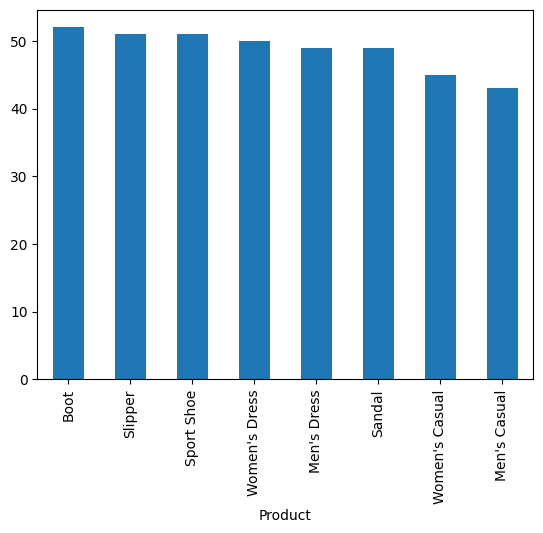

In [26]:
d1.plot(kind='bar', x = "Frequencies", y = "Product")

<Axes: ylabel='count'>

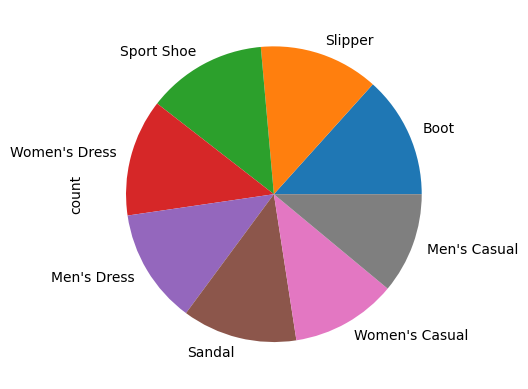

In [27]:
d1.plot(kind='pie')

In [28]:
d2 = df.groupby("Region")["Sales"].sum()  # summing the sales grouped by region
d2

Region
Africa                       2342588
Asia                          460231
Canada                       2041054
Central America/Caribbean    3081641
Eastern Europe               2394940
Middle East                  4333062
Pacific                      2296794
South America                2434783
United States                5503986
Western Europe               4873000
Name: Sales, dtype: int64

<Axes: xlabel='Region'>

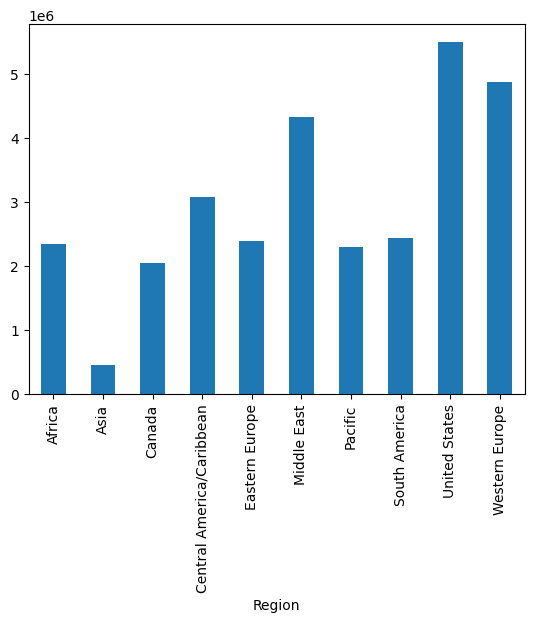

In [29]:
d2.plot(kind='bar')

In [30]:
d3 = df.groupby("Product")["Sales"].sum()
d3

Product
Boot              2350543
Men's Casual      6058878
Men's Dress       4749445
Sandal             868436
Slipper           5475321
Sport Shoe         651467
Women's Casual    4137861
Women's Dress     5470128
Name: Sales, dtype: int64

<Axes: xlabel='Product'>

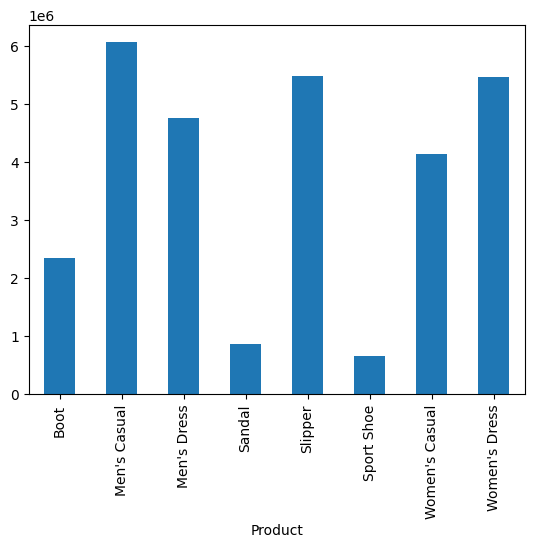

In [31]:
d3.plot(kind='bar')

In [32]:
pd.crosstab(df["Region"], df["Product"])  # creating a cross-tabulation of 'Region' and 'Product'
#crosstab counts the occurrences/frequencies of each combination of 'Region' and 'Product'
#both 'Region' and 'Product' are categorical variables, and crosstab provides a summary of their relationship

Product,Boot,Men's Casual,Men's Dress,Sandal,Slipper,Sport Shoe,Women's Casual,Women's Dress
Region,,,,,,,,
Africa,8,5,7,8,8,8,4,8
Asia,2,1,2,2,2,2,2,1
Canada,5,4,3,5,4,5,4,4
Central America/Caribbean,4,3,4,4,4,4,4,4
Eastern Europe,4,4,4,3,4,4,4,4
Middle East,3,2,3,3,3,3,3,3
Pacific,6,5,6,6,6,5,5,6
South America,7,6,7,7,7,7,6,7
United States,5,5,5,5,5,5,5,5


In [33]:
pd.pivot_table(data=df, index='Region', columns='Product', values='Stores', aggfunc='mean')  # creating a pivot table with 'Region' as index, 'Product' as columns, and mean of 'Stores' as values

Product,Boot,Men's Casual,Men's Dress,Sandal,Slipper,Sport Shoe,Women's Casual,Women's Dress
Region,,,,,,,,
Africa,17.500000,7.400000,5.142857,14.125000,11.375000,6.625000,4.500000,5.500000
Asia,9.000000,1.000000,4.000000,2.000000,11.000000,1.000000,1.500000,7.000000
Canada,17.000000,7.750000,4.666667,6.600000,12.500000,20.200000,6.750000,6.250000
Central America/Caribbean,25.500000,2.666667,9.500000,28.000000,25.000000,11.000000,8.250000,18.500000
Eastern Europe,20.500000,9.000000,8.250000,3.333333,18.250000,20.750000,3.250000,12.250000
Middle East,15.000000,26.500000,23.666667,14.333333,21.333333,3.666667,17.000000,16.000000
Pacific,12.833333,5.400000,8.000000,9.833333,10.833333,5.800000,2.800000,6.166667
South America,15.714286,5.166667,6.714286,21.285714,16.857143,12.428571,2.833333,10.428571
United States,15.800000,15.400000,18.600000,4.600000,14.800000,23.400000,7.200000,23.600000


In [34]:
pd.pivot_table(data=df, index='Region', columns='Product', values='Stores', aggfunc='sum') # creating a pivot table to summarize the data

Product,Boot,Men's Casual,Men's Dress,Sandal,Slipper,Sport Shoe,Women's Casual,Women's Dress
Region,,,,,,,,
Africa,140,37,36,113,91,53,18,44
Asia,18,1,8,4,22,2,3,7
Canada,85,31,14,33,50,101,27,25
Central America/Caribbean,102,8,38,112,100,44,33,74
Eastern Europe,82,36,33,10,73,83,13,49
Middle East,45,53,71,43,64,11,51,48
Pacific,77,27,48,59,65,29,14,37
South America,110,31,47,149,118,87,17,73
United States,79,77,93,23,74,117,36,118


In [35]:
pd.pivot_table(data=df, index='Region', columns='Product', values='Sales', aggfunc='sum')

Product,Boot,Men's Casual,Men's Dress,Sandal,Slipper,Sport Shoe,Women's Casual,Women's Dress
Region,,,,,,,,
Africa,119835,562794,318500,190409,337076,22150,417516,374308
Asia,62708,11754,119366,8208,152032,2092,25837,78234
Canada,385613,441903,162303,14798,252238,140389,410807,233003
Central America/Caribbean,190743,180401,404895,378382,883181,26964,399357,617718
Eastern Europe,306785,576396,335761,3716,509698,91202,209256,362126
Middle East,171282,759537,839571,35186,662480,4007,748792,1112207
Pacific,123575,662368,426191,48424,390740,26169,219886,399441
South America,245675,544950,425669,165925,462651,33061,179227,377625
United States,448296,1372527,969271,12039,967927,104403,541536,1087987


In [36]:
df

,Region,Product,Subsidiary,Stores,Sales,Inventory,Returns
0,Africa,Boot,Addis Ababa,12,29761,191821,769
1,Africa,Men's Casual,Addis Ababa,4,67242,118036,2284
2,Africa,Men's Dress,Addis Ababa,7,76793,136273,2433
3,Africa,Sandal,Addis Ababa,10,62819,204284,1861
4,Africa,Slipper,Addis Ababa,14,68641,279795,1771
...,...,...,...,...,...,...,...
385,Western Europe,Sandal,Rome,3,1249,4611,48
386,Western Europe,Slipper,Rome,13,42442,132283,1829
387,Western Europe,Sport Shoe,Rome,14,9969,74848,549
388,Western Europe,Women's Casual,Rome,2,19964,62256,954


<Axes: >

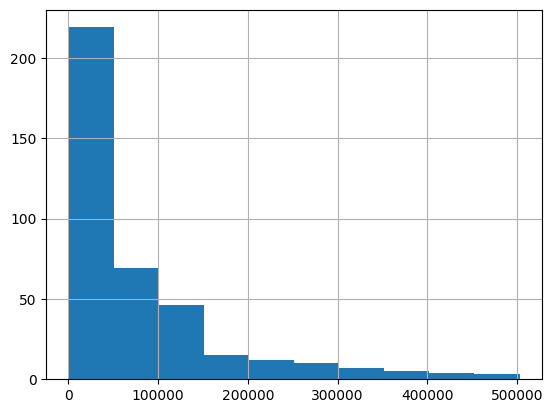

In [37]:
# histogram
# df["Sales"].hist(bins=20, edgecolor='black', title='Histogram of Sales')  # creating a histogram of the 'Sales' column with 20 bins and black edges
# df["Sales"].hist(bins=20, edgecolor='black')  # creating a histogram of the 'Sales' column with 20 bins and black edges
# df["Sales"].hist(bins=20, edgecolor='black', alpha=0.7)  # adding transparency to the histogram bars
# df["Sales"].hist(bins=20, edgecolor='black', alpha=0.7, color='blue')  # changing the color of the histogram bars to blue
# df["Sales"].hist(bins=20, edgecolor='black', alpha=0.7, color='blue', grid=False)  # removing the grid lines from the histogram
# df["Sales"].hist(bins=20, edgecolor='black', alpha=0.7, color='blue', grid=False, figsize=(10, 6))  # setting the figure size for the histogram
df["Sales"].hist()

In [38]:
df["Sales"].mode()[0]

1190

<Axes: title={'center': 'Boxplot of Sales'}>

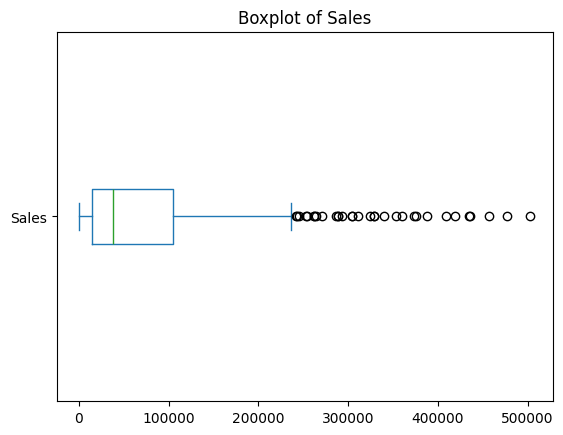

In [39]:
# Boxplot
boxplot = df['Sales'].plot(kind='box',vert = False, title="Boxplot of Sales")  
boxplot

<Axes: title={'center': 'Boxplot of Returns'}>

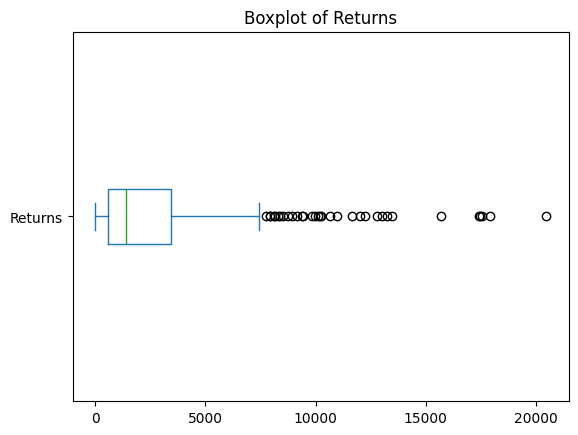

In [40]:
df['Returns'].plot(kind='box', vert=False, title='Boxplot of Returns')

<Axes: title={'center': 'Boxplot of Sales after removing outliers'}>

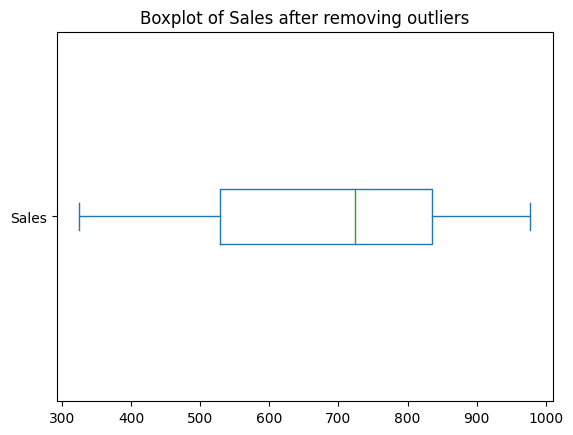

In [41]:
# Remove outliers
df = df[(df['Sales'] < 1000) & (df['Sales'] > 0)]  # assuming Sales should be between 0 and 1000
df['Sales'].plot(kind='box', vert=False, title='Boxplot of Sales after removing outliers')

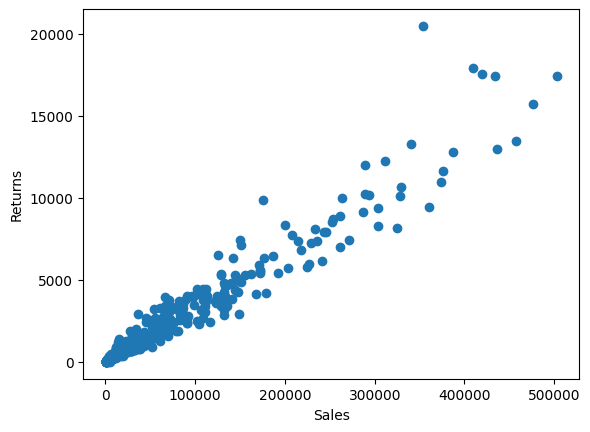

In [44]:
# Scatter plot
import matplotlib.pyplot as plt
plt.scatter(df["Sales"], df["Returns"])
plt.xlabel('Sales')
plt.ylabel('Returns')
plt.show()  # to display the plots
